# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Naufal Adlii Assegaf]
- **Email:** [assegafnaufal6332gmail.com]
- **ID Dicoding:** [naufal_adlii_asski7l]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata jumlah penyewaan sepeda per jam antara pengguna casual dengan pengguna registered pada hari kerja (working day) dibandingkan akhir pekan/hari libur (weekend/holiday) selama tahun 2012 untuk menentukan jadwal penempatan ulang armada yang optimal?

- **Pertanyaan 2:** Seberapa besar persentase penurunan rata-rata penyewaan sepeda harian pada kondisi cuaca buruk (weathersit 3 dan 4) dibandingkan cuaca cerah (weathersit 1) di setiap musim selama periode 2011-2012 untuk menjadwalkan pemeliharaan armada dan strategi promosi?

## Import Semua Packages/Library yang Digunakan

In [ ]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [1]:
import pandas as pd

hour_df = pd.read_csv('data/hour.csv')
day_df = pd.read_csv('data/day.csv')

display(hour_df.head())
display(day_df.head())

Mounted at /content/drive


**Insight:** (Opsional)
- df diakses dari dataset yang diupload ke google drive pengguna secara langsung

### Assessing Data

#### Identifying ... problem

In [4]:
for name, df in [('hour_df', hour_df), ('day_df', day_df)]:
    print(f"ASSESSING {name}")
    df.info()
    print(f"Missing values:\n{df.isna().sum()[df.isna().sum() > 0]}")
    print(f"Jumlah duplikasi: {df.duplicated().sum()}")

    hum_zero = (df['hum'] == 0).sum()
    print(f"Jumlah data dengan kelembapan (hum) = 0: {hum_zero}")

    print("Jumlah Outlier (metode IQR):")
    for col in ['casual', 'registered', 'cnt']:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        outliers = df[(df[col] < lower) | (df[col] > upper)].shape[0]
        print(f"  - {col}: {outliers} outlier")
    print("\n" + "="*45 + "\n")

ASSESSING hour_df
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB
Missing values:
Series([], dtyp

**Steps to Take:**
- Mengubah tipe data kolom `dteday` dari `object` menjadi `datetime` pada tabel `hour_df` dan `day_df` agar sesuai dengan format tanggal.
- Mengonversi nilai angka pada kolom kategorikal (`season`, `yr`, `weathersit`, dan `workingday`) menjadi label teks yang deskriptif (seperti *Spring, Summer, Fall, Winter* atau *2011, 2012*) agar lebih mudah dipahami saat proses analisis dan visualisasi.
- Pada `hour_df`, terdeteksi outlier pada kolom `casual` (1.192), `registered` (680), dan `cnt` (505). Sedangkan pada `day_df`, terdeteksi outlier pada kolom `casual` (44), sementara `registered` dan `cnt` memiliki 0 outlier. Outlier pada kolom jumlah penyewaan (`casual`, `registered`, `cnt`) akan dipertahankan karena merupakan lonjakan permintaan yang valid di dunia nyata (seperti jam rush hour atau hari libur cerah), bukan kesalahan pencatatan.
- Tidak diperlukan penanganan *missing values* maupun data duplikat karena kedua tabel sudah bersih (0 *missing value* dan 0 duplikasi).

**Insight:** (Opsional)
- xxx
- xxx

### Cleaning Data

#### Fixing ... problem

In [6]:
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
weather_map = {
    1: 'Clear',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}
workingday_map = {0: 'Weekend/Holiday', 1: 'Working Day'}

for df in [hour_df, day_df]:
    df['season'] = df['season'].map(season_map)
    df['yr'] = df['yr'].map(yr_map)
    df['weathersit'] = df['weathersit'].map(weather_map)
    df['workingday'] = df['workingday'].map(workingday_map)

print("INFO hour_df SETELAH CLEANING")
hour_df.info()
display(hour_df.head())

print("\nINFO day_df SETELAH CLEANING")
day_df.info()
display(day_df.head())

INFO hour_df SETELAH CLEANING
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  object        
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  object        
 9   weathersit  17379 non-null  object        
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64       

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,2011,1,0,0,6,Weekend/Holiday,Clear,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,Spring,2011,1,1,0,6,Weekend/Holiday,Clear,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,Spring,2011,1,2,0,6,Weekend/Holiday,Clear,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,Spring,2011,1,3,0,6,Weekend/Holiday,Clear,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,Spring,2011,1,4,0,6,Weekend/Holiday,Clear,0.24,0.2879,0.75,0.0,0,1,1



INFO day_df SETELAH CLEANING
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    object        
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    object        
 8   weathersit  731 non-null    object        
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
d

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,2011,1,0,6,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,2011,1,0,0,Weekend/Holiday,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,2011,1,0,1,Working Day,Clear,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,2011,1,0,2,Working Day,Clear,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,2011,1,0,3,Working Day,Clear,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- xxx
- xxx

## Exploratory Data Analysis (EDA)

### Explore ...

In [ ]:
hour_2012 = hour_df[hour_df['yr'] == 2012]

eda_q1 = (
    hour_2012.groupby(['workingday', 'hr'])[['casual', 'registered', 'cnt']]
    .mean()
    .round(2)
    .reset_index()
)

print("RINGKASAN RATA-RATA PENYEWAAN PER JAM (2012)")
display(eda_q1)

print("\nJAM PUNCAK PENYEWAAN (2012)")
if eda_q1.empty:
    print("Data untuk tahun 2012 tidak ditemukan atau kosong. Silakan periksa kembali proses cleaning pada kolom 'yr'.")
else:
    for day_type in ['Working Day', 'Weekend/Holiday']:
        subset = eda_q1[eda_q1['workingday'] == day_type]
        if not subset.empty:
            peak_reg = subset.loc[subset['registered'].idxmax()]
            peak_cas = subset.loc[subset['casual'].idxmax()]

            print(f"--- {day_type} ---")
            print(f"Puncak Registered : Jam {int(peak_reg['hr']):02d}:00 (rata-rata {peak_reg['registered']} sepeda/jam)")
            print(f"Puncak Casual     : Jam {int(peak_cas['hr']):02d}:00 (rata-rata {peak_cas['casual']} sepeda/jam)")
        else:
            print(f"--- {day_type} --- Data tidak tersedia.")

RINGKASAN RATA-RATA PENYEWAAN PER JAM (2012)


,workingday,hr,casual,registered,cnt
0,Weekend/Holiday,0,17.58,90.93,108.51
1,Weekend/Holiday,1,14.39,70.14,84.53
2,Weekend/Holiday,2,11.37,51.74,63.11
3,Weekend/Holiday,3,6.53,23.39,29.91
4,Weekend/Holiday,4,2.50,7.36,9.85
5,Weekend/Holiday,5,1.85,8.22,10.07
6,Weekend/Holiday,6,4.22,19.13,23.35
7,Weekend/Holiday,7,9.67,44.96,54.63
8,Weekend/Holiday,8,23.83,110.79,134.62
9,Weekend/Holiday,9,54.70,160.47,215.16



JAM PUNCAK PENYEWAAN (2012)
--- Working Day ---
Puncak Registered : Jam 17:00 (rata-rata 586.41 sepeda/jam)
Puncak Casual     : Jam 17:00 (rata-rata 69.78 sepeda/jam)
--- Weekend/Holiday ---
Puncak Registered : Jam 12:00 (rata-rata 299.22 sepeda/jam)
Puncak Casual     : Jam 14:00 (rata-rata 167.77 sepeda/jam)


In [ ]:
bad_weather = ['Light Snow/Rain', 'Heavy Rain/Snow']
weather_eda = day_df[day_df['weathersit'].isin(['Clear'] + bad_weather)].copy()

weather_eda['weather_group'] = weather_eda['weathersit'].apply(
    lambda x: 'Clear' if x == 'Clear' else 'Bad Weather'
)

eda_q2 = (
    weather_eda.pivot_table(
        index='season',
        columns='weather_group',
        values='cnt',
        aggfunc='mean'
    )
    .reindex(['Spring', 'Summer', 'Fall', 'Winter'])
)

eda_q2['Drop (%)'] = ((eda_q2['Clear'] - eda_q2['Bad Weather']) / eda_q2['Clear'] * 100)

print("RATA-RATA PENYEWAAN HARIAN & PENURUNAN SAAT CUACA BURUK (2011–2012)")
display(eda_q2.round(2))

RATA-RATA PENYEWAAN HARIAN & PENURUNAN SAAT CUACA BURUK (2011–2012)


weather_group,Bad Weather,Clear,Drop (%)
season,,,
Spring,934.75,2811.14,66.75
Summer,1169.00,5548.55,78.93
Fall,2751.75,5878.26,53.19
Winter,1961.60,5043.56,61.11


**Insight:** (Opsional)

Pertanyaan 1:
- Pola dua puncak (Bimodal) di Hari Kerja: Pada Working Day, penyewaan didominasi kuat oleh pengguna registered (komuter) dengan dua lonjakan tajam yaitu di puncak pagi (08:00): Rata-rata mencapai 580,20 sepeda/jam untuk registered (total cnt 604,51), lalu turun drastis pada pukul 10:00–15:00 (kisaran 130–200 registered). Kemudian di puncak sore (17:00–18:00): Memuncak pada pukul 17:00 dengan 586,41 registered dan 69,78 casual (total cnt 656,19), serta tetap sangat tinggi di pukul 18:00 (total cnt 617,00).

- Pola satu puncak (Unimodal) di Akhir Pekan: Pada Weekend/Holiday, permintaan membentuk satu kurva lebar di siang hingga sore hari (pukul 11:00–17:00, seluruhnya di atas 390 sepeda/jam). Total penyewaan (cnt) tertinggi terjadi pada pukul 13:00 (458,91 sepeda/jam), dengan puncak registered pada pukul 12:00 (299,22) dan lonjakan casual lebih dari 2 kali lipat hari kerja yang memuncak pada pukul 14:00 (167,77).

- Waktu Sepi untuk Rebalancing Armada: Titik terendah pada Working Day terjadi pukul 03:00–04:00 (total cnt hanya 5,49–6,03 sepeda/jam), sedangkan pada Weekend/Holiday pukul 04:00–05:00 (9,85–10,07 sepeda/jam).


Pertanyaan 2:
- Penurunan Drastis di Semua Musim: Cuaca buruk (Bad Weather) secara konsisten menurunkan rata-rata penyewaan sepeda harian lebih dari 50% di setiap musim dibandingkan saat cuaca cerah (Clear).
- Penurunan Terbesar (Summer): Musim Summer mengalami penurunan persentase paling tajam sebesar 78,93% (turun dari rata-rata 5.548,55 menjadi 1.169,00 penyewaan/hari), diikuti oleh Spring sebesar 66,75% (dari 2.811,14 menjadi 934,75 penyewaan/hari).
- Penurunan Terkecil (Fall): Musim Fall menjadi musim dengan rata-rata penyewaan tertinggi baik saat cuaca cerah (5.878,26) maupun cuaca buruk (2.751,75), dengan persentase penurunan paling rendah yakni 53,19%. Diikuti posisi kedua yaitu musim Winter yang mengalami penurunan sebesar 61,11% (dari 5.043,56 menjadi 1.961,60 penyewaan/hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

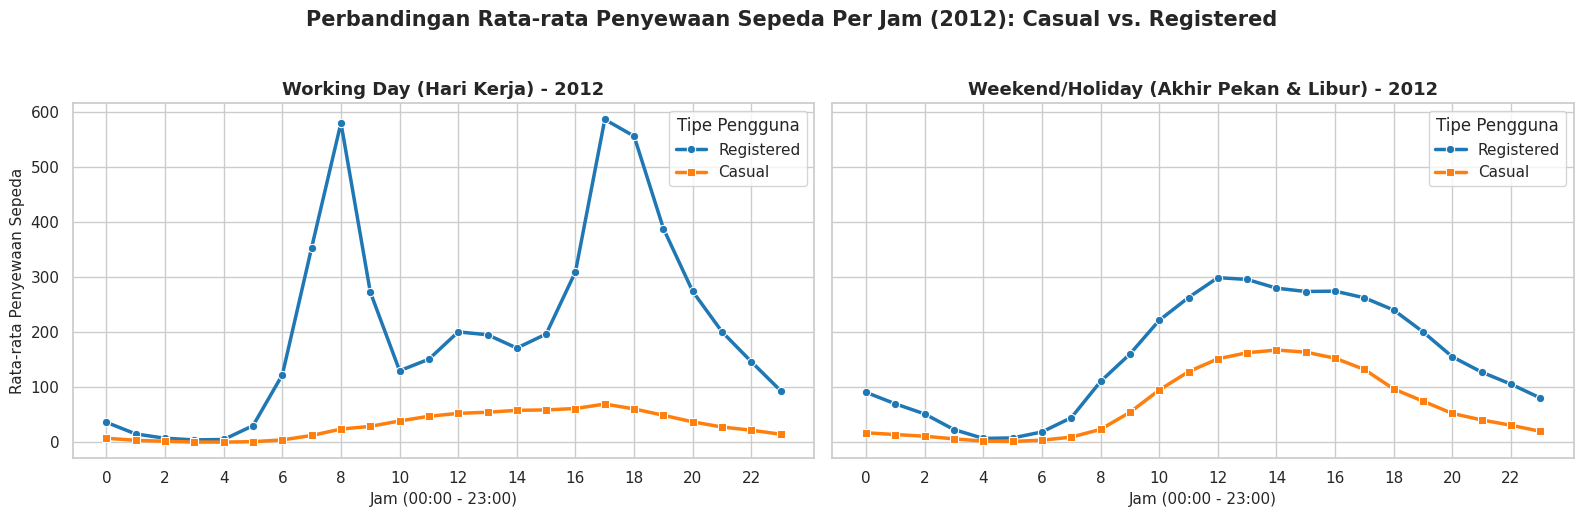

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

day_types = ['Working Day', 'Weekend/Holiday']
titles = [
    'Working Day (Hari Kerja) - 2012',
    'Weekend/Holiday (Akhir Pekan & Libur) - 2012'
]

for ax, day_type, title in zip(axes, day_types, titles):
    data_plot = eda_q1[eda_q1['workingday'] == day_type]

    sns.lineplot(data=data_plot, x='hr', y='registered', label='Registered', marker='o', linewidth=2.5, color='#1f77b4', ax=ax)
    sns.lineplot(data=data_plot, x='hr', y='casual', label='Casual', marker='s', linewidth=2.5, color='#ff7f0e', ax=ax)

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Jam (00:00 - 23:00)', fontsize=11)
    ax.set_ylabel('Rata-rata Penyewaan Sepeda', fontsize=11)
    ax.set_xticks(range(0, 24, 2))
    ax.legend(title='Tipe Pengguna')

fig.suptitle('Perbandingan Rata-rata Penyewaan Sepeda Per Jam (2012): Casual vs. Registered', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

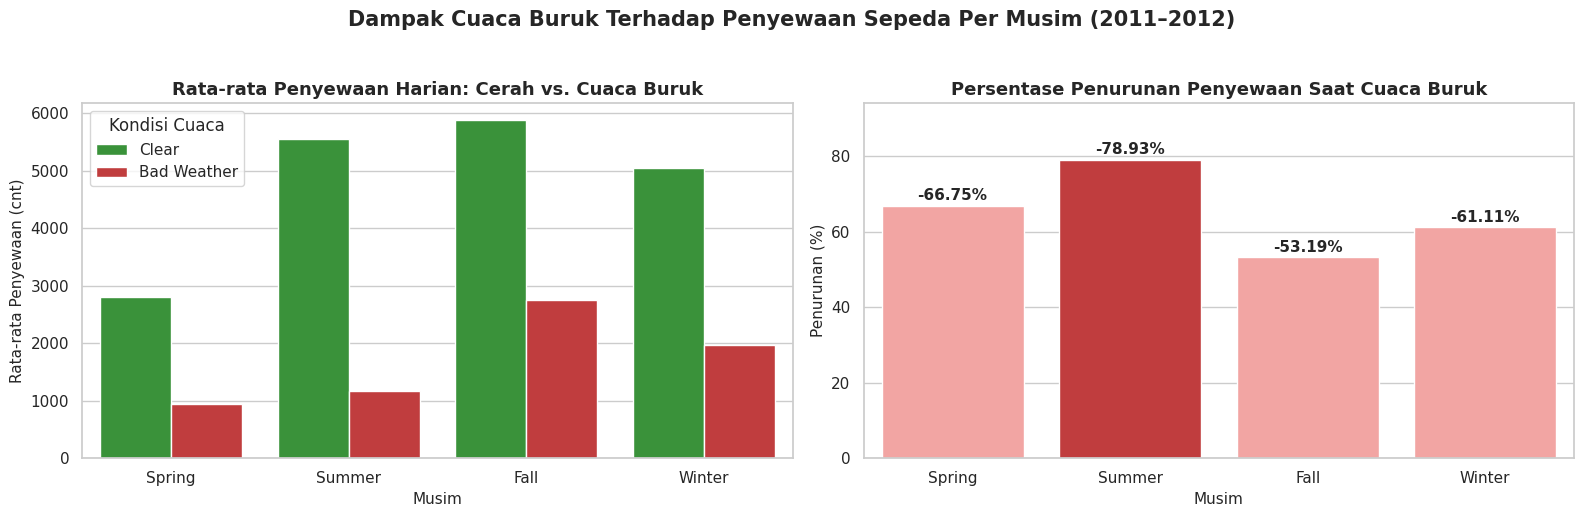

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Grafik Kiri: Perbandingan Rata-rata Penyewaan (Clear vs Bad Weather)
plot_melted = eda_q2[['Clear', 'Bad Weather']].reset_index().melt(
    id_vars='season',
    var_name='Kondisi Cuaca',
    value_name='Rata-rata Penyewaan'
)

sns.barplot(
    data=plot_melted,
    x='season',
    y='Rata-rata Penyewaan',
    hue='Kondisi Cuaca',
    palette={'Clear': '#2ca02c', 'Bad Weather': '#d62728'},
    ax=axes[0]
)
axes[0].set_title('Rata-rata Penyewaan Harian: Cerah vs. Cuaca Buruk', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Musim', fontsize=11)
axes[0].set_ylabel('Rata-rata Penyewaan (cnt)', fontsize=11)
axes[0].legend(title='Kondisi Cuaca')

# Grafik Kanan: Persentase Penurunan (%)
colors = ['#d62728' if val == eda_q2['Drop (%)'].max() else '#ff9896' for val in eda_q2['Drop (%)']]

sns.barplot(
    x=eda_q2.index,
    y=eda_q2['Drop (%)'],
    palette=colors,
    hue=eda_q2.index,
    legend=False,
    ax=axes[1]
)

# Menambahkan label angka persentase di atas batang
for i, val in enumerate(eda_q2['Drop (%)']):
    axes[1].text(i, val + 1.5, f"-{val:.2f}%", ha='center', fontweight='bold', fontsize=11)

axes[1].set_title('Persentase Penurunan Penyewaan Saat Cuaca Buruk', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Musim', fontsize=11)
axes[1].set_ylabel('Penurunan (%)', fontsize=11)
axes[1].set_ylim(0, eda_q2['Drop (%)'].max() + 15)

fig.suptitle('Dampak Cuaca Buruk Terhadap Penyewaan Sepeda Per Musim (2011–2012)', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik Pertanyaan 1 memperlihatkan adanya perbedaan bentuk kurva yang sangat kontras: pola dua puncak (bimodal) pada Working Day yang didominasi komuter registered pada pukul 08:00 dan 17:00–18:00 atau bisa dibilang pada waktu rush hour, hal ini berbanding terbalik dengan pola satu puncak (unimodal) yang cenderung memuncak di siang hari (11:00–17:00) pada Weekend/Holiday dengan lonjakan signifikan dari pengguna casual.
- Grafik Pertanyaan 2 menegaskan bahwa cuaca buruk (bad weather) memangkas lebih dari separuh permintaan harian di seluruh musim, dengan Summer menjadi musim yang paling terdampak (-78,93%) dan Fall menjadi musim yang paling tidak terdampak (tangguh) (-53,19%).

## Analisis Lanjutan (Opsional)

RINGKASAN KLASTER WAKTU PENYEWAAN (2012)


,workingday,time_cluster,total_rentals,avg_rentals,avg_casual,avg_registered,share_pct
0,Weekend/Holiday,1. Dini Hari (00-05),35361,51.099711,9.049133,42.050578,5.76
1,Weekend/Holiday,2. Rush Hour Pagi (06-09),49621,106.941810,23.105603,83.836207,8.09
2,Weekend/Holiday,3. Siang (10-15),290522,417.416667,145.034483,272.382184,47.36
3,Weekend/Holiday,4. Rush Hour Sore (16-19),166587,359.023707,114.390086,244.633621,27.16
4,Weekend/Holiday,5. Malam (20-23),71339,153.747845,36.271552,117.476293,11.63
5,Working Day,1. Dini Hari (00-05),28974,19.590264,2.796484,16.793780,2.02
6,Working Day,2. Rush Hour Pagi (06-09),347437,350.238911,17.715726,332.523185,24.19
7,Working Day,3. Siang (10-15),337471,226.338699,51.973172,174.365526,23.50
8,Working Day,4. Rush Hour Sore (16-19),518541,520.623494,60.416667,460.206827,36.11
9,Working Day,5. Malam (20-23),203723,204.541165,25.656627,178.884538,14.19


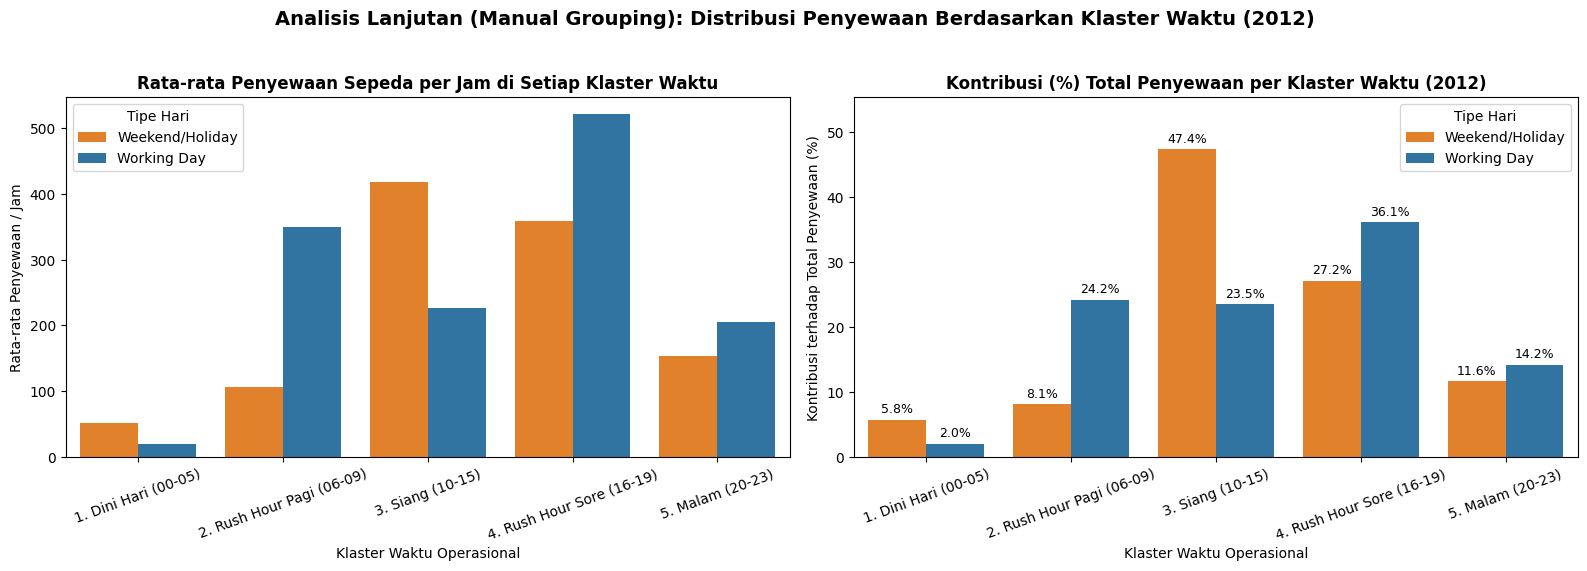

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def categorize_time_cluster(hr):
    if 0 <= hr <= 5:
        return '1. Dini Hari (00-05)'
    elif 6 <= hr <= 9:
        return '2. Rush Hour Pagi (06-09)'
    elif 10 <= hr <= 15:
        return '3. Siang (10-15)'
    elif 16 <= hr <= 19:
        return '4. Rush Hour Sore (16-19)'
    else:
        return '5. Malam (20-23)'

hour_2012_cluster = hour_df[hour_df['yr'] == 2012].copy()
hour_2012_cluster['time_cluster'] = hour_2012_cluster['hr'].apply(categorize_time_cluster)

cluster_summary = (
    hour_2012_cluster.groupby(['workingday', 'time_cluster'])
    .agg(
        total_rentals=('cnt', 'sum'),
        avg_rentals=('cnt', 'mean'),
        avg_casual=('casual', 'mean'),
        avg_registered=('registered', 'mean')
    )
    .reset_index()
)

cluster_summary['share_pct'] = (
    cluster_summary['total_rentals'] /
    cluster_summary.groupby('workingday')['total_rentals'].transform('sum') * 100
).round(2)

print("RINGKASAN KLASTER WAKTU PENYEWAAN (2012)")
display(cluster_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.barplot(
    data=cluster_summary,
    x='time_cluster',
    y='avg_rentals',
    hue='workingday',
    palette={'Working Day': '#1f77b4', 'Weekend/Holiday': '#ff7f0e'},
    ax=axes[0]
)
axes[0].set_title('Rata-rata Penyewaan Sepeda per Jam di Setiap Klaster Waktu', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Klaster Waktu Operasional', fontsize=10)
axes[0].set_ylabel('Rata-rata Penyewaan / Jam', fontsize=10)
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(title='Tipe Hari')

sns.barplot(
    data=cluster_summary,
    x='time_cluster',
    y='share_pct',
    hue='workingday',
    palette={'Working Day': '#1f77b4', 'Weekend/Holiday': '#ff7f0e'},
    ax=axes[1]
)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

axes[1].set_title('Kontribusi (%) Total Penyewaan per Klaster Waktu (2012)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Klaster Waktu Operasional', fontsize=10)
axes[1].set_ylabel('Kontribusi terhadap Total Penyewaan (%)', fontsize=10)
axes[1].set_ylim(0, cluster_summary['share_pct'].max() + 8)
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend(title='Tipe Hari')

fig.suptitle('Analisis Lanjutan (Manual Grouping): Distribusi Penyewaan Berdasarkan Klaster Waktu (2012)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Manual Grouping (Binning) dengan mengelompokkan 24 jam operasional (`hr`) ke dalam 5 klaster waktu berdasarkan aktivitas harian:
1. Dini Hari (00:00–05:00):
Fase istirahat/aktivitas minimal.
2. Rush Hour Pagi (06:00–09:00):
Jam sibuk berangkat kerja/sekolah.
3. Siang (10:00–15:00):
Jam operasional tengah hari dan aktivitas rekreasi.
4. Rush Hour Sore (16:00–19:00):
Jam sibuk pulang kerja.
5. Malam (20:00–23:00):
Fase aktivitas malam hari.

- Konsentrasi Beban di Jam Sibuk pada Hari Kerja (Working Day)
Lebih dari separuh total penyewaan harian (60,30%) terkonsentrasi pada dua klaster jam sibuk komuter, yaitu Rush Hour Sore (16:00–19:00) sebesar 36,11% (518.541 penyewaan; rata-rata 520,62 sepeda/jam) dan Rush Hour Pagi (06:00–09:00) sebesar 24,19% (347.437 penyewaan; rata-rata 350,24 sepeda/jam).   

- Dominasi Klaster Siang di Akhir Pekan (Weekend/Holiday)
Hampir separuh dari seluruh aktivitas penyewaan akhir pekan terpusat pada klaster Siang (10:00–15:00) yang menyumbang 47,36% (290.522 penyewaan; rata-rata 417,42 sepeda/jam), diikuti oleh Rush Hour Sore (16:00–19:00) sebesar 27,16% (166.587 penyewaan; rata-rata 359,02 sepeda/jam). Jika digabungkan, rentang waktu pukul 10:00 hingga 19:00 mencakup 74,52% dari total penyewaan akhir pekan.   

- Kontras Aktivitas Pagi vs Dini Hari: Pada Weekend/Holiday, klaster Rush Hour Pagi (06:00–09:00) hanya berkontribusi 8,09% (jauh di bawah hari kerja yang mencapai 24,19%). Sebaliknya, aktivitas pada klaster Dini Hari (00:00–05:00) di akhir pekan justru lebih aktif dengan kontribusi 5,76% (rata-rata 51,10 sepeda/jam) dibandingkan hari kerja yang hanya 2,02% (rata-rata 19,59 sepeda/jam).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada tahun 2012, pola penyewaan sepeda per jam menunjukkan perbedaan tajam antara hari kerja (working day) dan akhir pekan/hari libur (weekend/holiday). Pada Working Day, penyewaan didominasi oleh pengguna registered dengan pola dua puncak (bimodal), yaitu jam berangkat kerja pukul 08:00 (rata-rata 580,20 registered; total 604,51 sepeda/jam) dan jam pulang kerja pukul 17:00–18:00 (puncak 586,41 registered dan 69,78 casual; total 656,19 sepeda/jam). Sebaliknya, pada Weekend/Holiday, permintaan membentuk satu puncak (unimodal) di siang hingga sore hari (11:00–17:00) dengan total penyewaan tertinggi pukul 13:00 (458,91 sepeda/jam), puncak registered pukul 12:00 (299,22), dan lonjakan pengguna casual lebih dari dua kali lipat hari kerja yang memuncak pada pukul 14:00 (167,77 sepeda/jam).
- **Conclusion pertanyaan 2:** Selama periode 2011–2012, kondisi cuaca buruk (Light/Heavy Rain & Snow) menyebabkan penurunan rata-rata penyewaan sepeda harian lebih dari 50% di seluruh musim dibandingkan cuaca cerah. Penurunan paling drastis terjadi pada musim Summer sebesar 78,93% (dari 5.548,55 menjadi 1.169,00 sepeda/hari) dan posisi kedua Spring sebesar 66,75% (dari 2.811,14 menjadi 934,75 sepeda/hari). Sementara itu, posisi ketiga musim Winter turun sebesar 61,11% (dari 5.043,56 menjadi 1.961,60), dan musim Fall menjadi yang paling tidak terdampak dengan penurunan terendah sebesar 53,19% (dari 5.878,26 menjadi 2.751,75 sepeda/hari).

**Rekomendasi Action Item:**

- Penyesuaian Ketersediaan Sepeda Berdasarkan Tipe Hari dan Jam:
Pada hari kerja (Working Day), pastikan kapasitas sepeda tersedia secara maksimal menjelang dua klaster jam sibuk utama, yaitu Rush Hour Pagi (06:00–09:00) dan Rush Hour Sore (16:00–19:00), karena kedua klaster ini mencakup 60,30% dari total penyewaan harian (didominasi pengguna registered)

- Optimalisasi Armada Akhir Pekan/Liburan di Area Rekreasi:
Peningkatan Kapasitas Armada pada Siang Hari Akhir Pekan: Pada akhir pekan dan hari libur (Weekend/Holiday), fokuskan ketersediaan sepeda pada rentang pukul 10:00 hingga 19:00 (klaster Siang dan Rush Hour Sore) yang menyerap 74,52% total penyewaan, serta rancang program promosi konversi keanggotaan (registered) bagi pengguna casual pada jam-jam tersebut.

- Penjadwalan Maintenance Berbasis Prakiraan Cuaca:
Jadwalkan perawatan rutin dan perbaikan besar armada pada hari-hari dengan prakiraan cuaca buruk, khususnya di musim Spring dan Summer saat volume penyewaan anjlok ke titik terendahnya (934–1.169 sepeda/hari), sehingga tidak mengganggu ketersediaan sepeda saat permintaan puncak di cuaca cerah, dikarenakan banyak armada yang menganggur pada waktu-waktu tersbut. Bisa pula memanfaatkan klaster Dini Hari (00:00–05:00) pada hari kerja—yang hanya memiliki kontribusi 2,02% (rata-rata 19,59 sepeda/jam)—untuk melakukan pengisian daya sistem stasiun, inspeksi rutin, dan distribusi ulang sepeda tanpa mengganggu layanan pengguna

- Strategi Promosi Musiman:
Rancang kampanye diskon atau paket berlangganan khusus di musim Spring (musim dengan rata-rata penyewaan terendah saat cuaca cerah maupun buruk) untuk menggenjot utilisasi armada, serta pastikan kapasitas maksimal siap digunakan sepanjang musim Fall yang memiliki permintaan paling stabil dibanding musim lainnya. Atau bisa juga melakukan kegiatan promosi keanggotaan (membership) bagi pengguna casual pada jam puncak akhir pekan/liburan.

